# 02 — Blank periods: missing data or real zeros?

Notebook 01 showed that most series contain long runs of zero sales. Before any model, we must
decide what those zeros **are**, because the two possible answers need opposite handling:

| | **Real zeros** | **Missing data** |
|---|---|---|
| what happened | the item was on sale and nobody bought it | there was nothing to observe (item not on sale) |
| value in the model's history | `0` | `NaN` (masked) |
| scored in the test window? | yes, it is the truth | never, we have no truth |

The `sell_prices.csv` file decides it: an item has a price in a given week only if it was on sale that week.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

from m5_chronos2.data import (
    ARTIFACTS_DIR,
    HORIZON,
    add_price,
    get_roster,
    list_all_series,
    load_prices,
    roster_name,
)
from m5_chronos2.blank_periods import (
    add_blank_flags,
    add_silent_runs,
    grouping_permutation_test,
    pairwise_blank_correlation,
    tolerate_shifts,
)
from m5_chronos2.plots import CATEGORY_COLORS, MAIN_COLOR, MUTED_TEXT_COLOR, use_blog_style

use_blog_style()

## Settings

Same sample as notebook 01. The two blank-period thresholds are discussed in section 4.

In [2]:
SAMPLE_SIZE = 500
SEED = 42

MIN_BLANK_DAYS = 14   # a blank period lasts at least two full weeks
LONG_BLANK_DAYS = HORIZON   # 28: a long blank period can cover a whole forecast window

## 1. Load the sample and its prices

In [3]:
roster = get_roster(list_all_series(), SAMPLE_SIZE, SEED)

sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_{roster_name(SAMPLE_SIZE, SEED)}.parquet")
sales = sales.select("id", "item_id", "dept_id", "cat_id", "store_id", "state_id", "date", "sales")

prices = load_prices(roster)
sales = add_price(sales, prices)

print(f"{prices.height:,} weekly price rows for {roster.height} series")
sales.head()

Reading the frozen roster: roster_n500_seed42.parquet
112,188 weekly price rows for 500 series


id,item_id,dept_id,cat_id,store_id,state_id,date,sales,sell_price,is_on_sale
str,str,str,str,str,str,date,i64,f64,bool
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-01-29,0,2.0,true
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-01-30,0,2.0,true
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-01-31,0,2.0,true
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-02-01,0,2.0,true
"""FOODS_1_001_WI_3_evaluation""","""FOODS_1_001""","""FOODS_1""","""FOODS""","""WI_3""","""WI""",2011-02-02,0,2.0,true


## 2. Diagnostic: is the raw table hiding missing data?

Every (series, day) pair has an explicit value in the sales file and none is null (checked in notebook 01).
So the sales file alone cannot tell "nothing sold" from "nothing to sell". The price file can.

**Check 1: do sales ever happen while the item has no price?** If the price file is a reliable
"on sale" signal, this count must be zero.

In [4]:
sold_without_price = sales.filter((pl.col("sales") > 0) & ~pl.col("is_on_sale")).height
print(f"Days with sales but no price: {sold_without_price}")

Days with sales but no price: 0


**Check 2: does each item's first price coincide with its first sale?** If yes, the zeros at the start
of a series are days when the item was not on sale yet: missing data, not demand.

In [5]:
per_series = sales.group_by("id").agg(
    pl.col("date").filter(pl.col("is_on_sale")).min().alias("first_price_date"),
    pl.col("date").filter(pl.col("sales") > 0).min().alias("first_sale_date"),
)
per_series = per_series.with_columns(
    (pl.col("first_sale_date") - pl.col("first_price_date")).dt.total_days().alias("days_price_to_sale")
)

print(f"First sale within the first week of price: {(per_series['days_price_to_sale'] < 7).mean():.1%} of series")
print("Largest delays (days):", per_series["days_price_to_sale"].sort(descending=True).head(5).to_list())

First sale within the first week of price: 99.4% of series
Largest delays (days): [884, 14, 8, 6, 6]


**Check 3: once an item has a price, does it ever lose it?** A week without price in the middle of a
series would be a gap of missing data.

In [6]:
price_gaps = sales.group_by("id").agg(
    # number of days without price that come after the first priced day
    (~pl.col("is_on_sale") & (pl.col("date") > pl.col("date").filter(pl.col("is_on_sale")).min()))
    .sum()
    .alias("days_without_price_after_start")
)
print(f"Series with a price gap after their start: {(price_gaps['days_without_price_after_start'] > 0).sum()}")

Series with a price gap after their start: 0


**Check 4: coverage over time.** Share of the sample on sale on each day. A missing-data problem
coming from the data pipeline would show as a sudden cliff shared by all series at once.

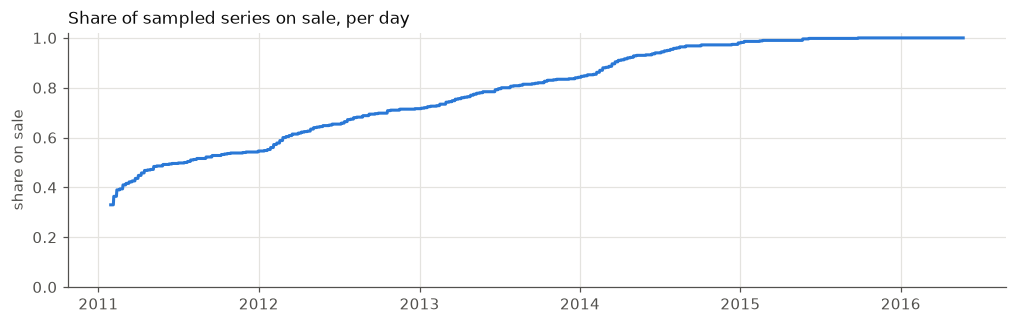

In [7]:
coverage = sales.group_by("date").agg(pl.col("is_on_sale").mean().alias("share_on_sale")).sort("date")

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(coverage["date"].to_numpy(), coverage["share_on_sale"].to_numpy(), color=MAIN_COLOR)
ax.set_ylim(0, 1.02)
ax.set_ylabel("share on sale")
ax.set_title("Share of sampled series on sale, per day", loc="left")
plt.show()

**Conclusion of section 2** : the days before an item's first price are
**missing data**, and they are the only missing data. Every other zero happened while the item was on
sale: it is a **real zero** of the target we forecast (units sold).

Note: a real zero of *sales* can still hide unobserved *demand* (an empty shelf). We forecast sales, so
for us it is the truth to predict.

We record this as an `is_missing` column, carried through every later notebook.

In [8]:
sales = sales.with_columns((~pl.col("is_on_sale")).alias("is_missing"))
print(f"Missing days: {sales['is_missing'].mean():.1%} of all (series, day) pairs")

Missing days: 20.8% of all (series, day) pairs


## 3. How long are the silences?

A day is **silent** when the item is on sale but sold nothing. For every run of consecutive silent days,
we measure its length.

In [9]:
sales = add_silent_runs(sales)

To count runs: count silent days by run length, then divide by the length (a run of 5 days contributes 5 silent days of length 5).

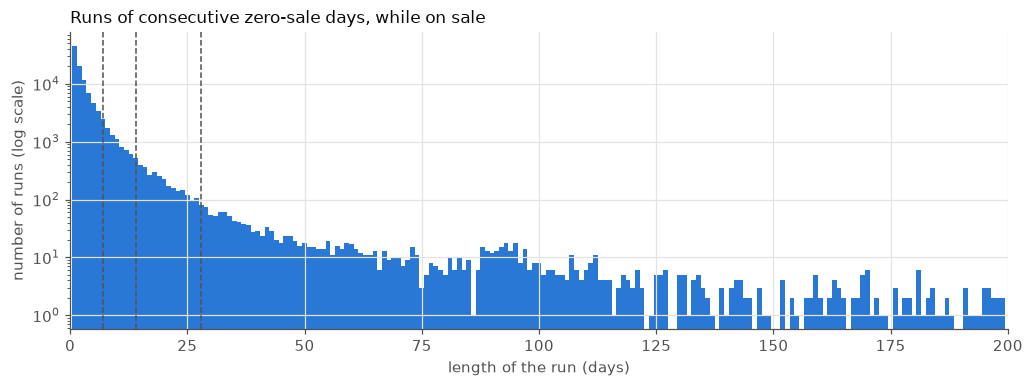

Silent days inside runs of 7+ days: 60%
Silent days inside runs of 14+ days: 43%
Silent days inside runs of 28+ days: 30%


In [10]:
runs = (
    sales.filter(pl.col("is_silent"))
    .group_by("silent_run_length")
    .agg(pl.len().alias("n_silent_days"))
    .with_columns((pl.col("n_silent_days") / pl.col("silent_run_length")).alias("n_runs"))
    .sort("silent_run_length")
)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(runs["silent_run_length"].to_numpy(), runs["n_runs"].to_numpy(), width=1, color=MAIN_COLOR)
ax.set_yscale("log")
ax.set_xlim(0, 200)
ax.set_xlabel("length of the run (days)")
ax.set_ylabel("number of runs (log scale)")
ax.set_title("Runs of consecutive zero-sale days, while on sale", loc="left")
for threshold in (7, MIN_BLANK_DAYS, LONG_BLANK_DAYS):
    ax.axvline(threshold, color=MUTED_TEXT_COLOR, linewidth=1, linestyle="--")
plt.show()

silent_days = runs["n_silent_days"].sum()
for threshold in (7, MIN_BLANK_DAYS, LONG_BLANK_DAYS):
    share = runs.filter(pl.col("silent_run_length") >= threshold)["n_silent_days"].sum() / silent_days
    print(f"Silent days inside runs of {threshold}+ days: {share:.0%}")

## 4. Defining a blank period

**Definition:** a blank period is a run of at least `MIN_BLANK_DAYS` consecutive days with zero sales
while the item is on sale.

Why these thresholds:
- the threshold must exceed the longest *natural* silence of the series. The natural cycle here is the
  week, so a silence must last more than one week to be unusual; two weeks (14 days) leaves a margin for
  slow-selling items;
- blank periods of `LONG_BLANK_DAYS` = 28 days or more are counted separately: such a period can cover an
  entire forecast window, which is a different problem from a short interruption.

No upper bound is needed: the price file tells us when an item stops being sold, and it never happens
in this data (check 3).

In [11]:
sales = add_blank_flags(sales, min_days=MIN_BLANK_DAYS, long_days=LONG_BLANK_DAYS)

blank_per_series = sales.group_by("id").agg(
    pl.col("is_blank").any().alias("has_blank"),
    (pl.col("blank_kind") == "long").any().alias("has_long_blank"),
    (pl.col("is_blank").sum() / pl.col("is_on_sale").sum()).alias("blank_share_of_on_sale_days"),
)

print(f"Series with at least one blank period: {blank_per_series['has_blank'].mean():.0%}")
print(f"Series with at least one long blank period: {blank_per_series['has_long_blank'].mean():.0%}")
print(f"Median share of on-sale days inside blank periods: {blank_per_series['blank_share_of_on_sale_days'].median():.0%}")

Series with at least one blank period: 94%
Series with at least one long blank period: 82%
Median share of on-sale days inside blank periods: 21%


## 5. Does the definition fire where we would expect?

The series of the sample with the most blank days. Shaded: blank periods. Gray band: not on sale (missing).

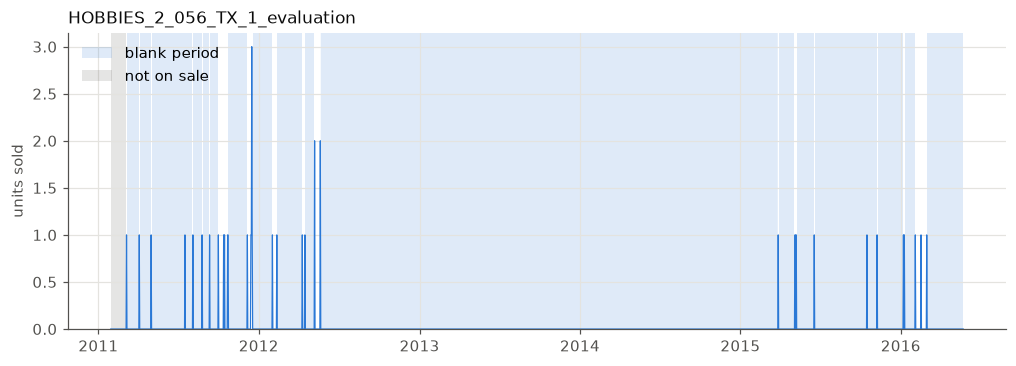

In [12]:
worst_id = blank_per_series.sort("blank_share_of_on_sale_days", descending=True)["id"][0]
one_series = sales.filter(pl.col("id") == worst_id)
dates = one_series["date"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(dates, one_series["sales"].to_numpy(), color=MAIN_COLOR, linewidth=0.8)
y_top = one_series["sales"].max() * 1.05
ax.fill_between(dates, 0, y_top, where=one_series["is_blank"].to_numpy(),
                color=MAIN_COLOR, alpha=0.15, linewidth=0, label="blank period")
ax.fill_between(dates, 0, y_top, where=one_series["is_missing"].to_numpy(),
                color=MUTED_TEXT_COLOR, alpha=0.15, linewidth=0, label="not on sale")
ax.set_ylim(0, y_top)
ax.set_ylabel("units sold")
ax.set_title(worst_id, loc="left")
ax.legend(loc="upper left")
plt.show()

## 6. The global view: one row per series, one column per day

Rows are sorted by store, then category. Gray: not on sale. Colored: blank period, colored by category.
If blank periods are driven by something shared (a store event, a holiday), we should see vertical
bands inside a store block.

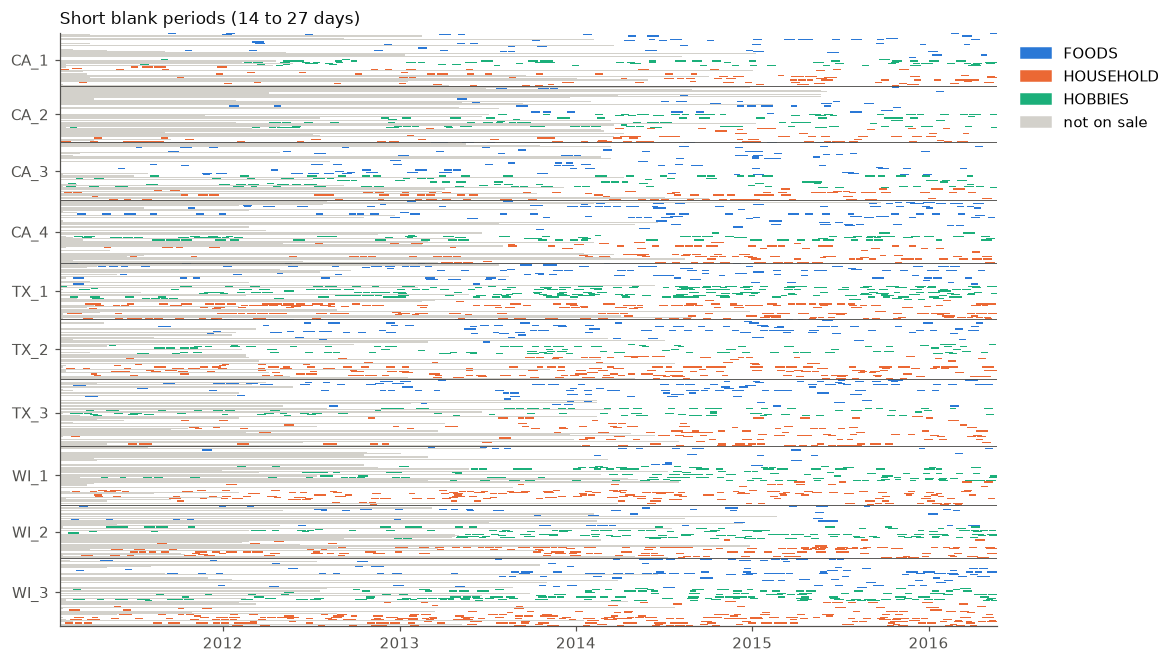

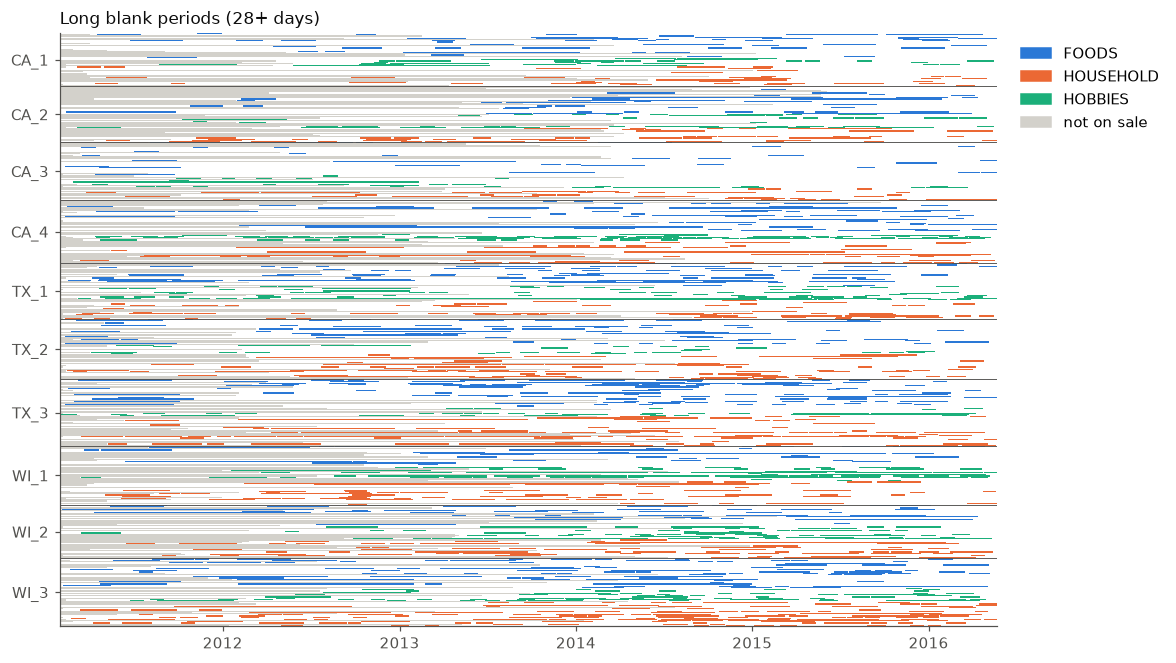

In [13]:
# Row order: by store, then category, then id
row_order = roster.sort("store_id", "cat_id", "id").with_row_index("row")
sales = sales.join(row_order.select("id", "row"), on="id", how="left")

first_date = sales["date"].min()
sales = sales.with_columns((pl.col("date") - first_date).dt.total_days().alias("col"))

n_rows = roster.height
n_cols = sales["col"].max() + 1

def blank_heatmap(kind, title):
    image = np.ones((n_rows, n_cols, 3))   # white background

    missing = sales.filter(pl.col("is_missing"))
    image[missing["row"].to_numpy(), missing["col"].to_numpy()] = to_rgb("#d3d1cb")

    for category, color in CATEGORY_COLORS.items():
        cells = sales.filter((pl.col("blank_kind") == kind) & (pl.col("cat_id") == category))
        image[cells["row"].to_numpy(), cells["col"].to_numpy()] = to_rgb(color)

    fig, ax = plt.subplots(figsize=(11, 7))
    ax.imshow(image, aspect="auto", interpolation="nearest")
    ax.grid(False)

    # one horizontal line between stores, store names on the y axis
    store_blocks = row_order.group_by("store_id").agg(
        pl.col("row").min().alias("start"), pl.col("row").max().alias("end")
    ).sort("start")
    for start in store_blocks["start"].to_list()[1:]:
        ax.axhline(start - 0.5, color=MUTED_TEXT_COLOR, linewidth=0.6)
    ax.set_yticks(((store_blocks["start"] + store_blocks["end"]) / 2).to_list())
    ax.set_yticklabels(store_blocks["store_id"].to_list())

    # x axis: one tick per year
    years = sales.filter(pl.col("date").dt.month() == 1, pl.col("date").dt.day() == 1).unique("date").sort("date")
    ax.set_xticks(years["col"].to_list())
    ax.set_xticklabels(years["date"].dt.year().to_list())

    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CATEGORY_COLORS.values()]
    handles.append(plt.Rectangle((0, 0), 1, 1, color="#d3d1cb"))
    ax.legend(handles, list(CATEGORY_COLORS) + ["not on sale"], loc="upper left",
              bbox_to_anchor=(1.01, 1), frameon=False)
    ax.set_title(title, loc="left")
    plt.show()

blank_heatmap("short", f"Short blank periods ({MIN_BLANK_DAYS} to {LONG_BLANK_DAYS - 1} days)")
blank_heatmap("long", f"Long blank periods ({LONG_BLANK_DAYS}+ days)")

### 6b. Are blank periods more alike within a category?

The heatmaps are read by eye. To decide whether **product category** is a useful grouping, we need a
number: are two series of the same category more likely to be blank at the same time than two series
taken at random?

A naive measure would read each series' blank periods as a long 0/1 vector and take the dot product of two
vectors. It fails in three ways:
1. **small shifts**: two blank periods caused by the same event but starting 2 days apart share no day,
   and count as unrelated;
2. **chance overlap**: two series that are each blank half of the time share many blank days even if they
   are unrelated. The dot product grows with how often a series is blank, not with how *related* two series are;
3. **different on-sale spans**: a series launched in 2014 cannot share a blank period with another in 2012.

The estimator below fixes each point:
1. every blank period is widened by `SHIFT_TOLERANCE_DAYS` on each side before comparing;
2. for each pair, we use the **correlation** of the two 0/1 vectors (the phi coefficient) instead of the dot
   product: it is 0 for unrelated series whatever their blank rates, and 1 for identical patterns;
3. each pair is compared only on the days when **both** series are on sale (at least `MIN_COMMON_DAYS`).

Then:
- **within** = mean correlation over pairs from the same category, **between** = over pairs from different
  categories, and the statistic is **within − between**;
- **is it more than chance?** We shuffle the category labels between series 1,000 times (group sizes
  unchanged) and recompute the statistic each time. If category does not matter, the observed value looks
  like the shuffled ones. The p-value is the share of shuffles that reach the observed value.

In [14]:
SHIFT_TOLERANCE_DAYS = 3   # blank periods up to 3 days apart count as simultaneous
MIN_COMMON_DAYS = 180      # a pair is compared only if both series were on sale 180+ common days
N_PERMUTATIONS = 1000

# Two matrices, one row per series (same order as the heatmaps), one column per day.
blank_matrix = np.zeros((n_rows, n_cols), dtype=bool)
blank_days = sales.filter(pl.col("is_blank"))
blank_matrix[blank_days["row"].to_numpy(), blank_days["col"].to_numpy()] = True

on_sale_matrix = np.zeros((n_rows, n_cols), dtype=bool)
on_sale_days = sales.filter(pl.col("is_on_sale"))
on_sale_matrix[on_sale_days["row"].to_numpy(), on_sale_days["col"].to_numpy()] = True

# The category of each row
category_labels = row_order.sort("row")["cat_id"].to_numpy()

Correlation of every pair of series (about 125,000 pairs for 500 series: this cell takes a little while).

In [15]:
correlation = pairwise_blank_correlation(
    tolerate_shifts(blank_matrix, SHIFT_TOLERANCE_DAYS), on_sale_matrix, MIN_COMMON_DAYS
)
result = grouping_permutation_test(correlation, category_labels, N_PERMUTATIONS, SEED)

print(f"Mean correlation, all pairs:               {result['all_pairs']:.4f}")
print(f"Mean correlation, same category:           {result['within']:.4f}")
print(f"Mean correlation, different categories:    {result['between']:.4f}")
print(f"Within - between: {result['gap']:.4f}   (z = {result['z_score']:.1f}, p = {result['p_value']:.3f})")

Mean correlation, all pairs:               0.0085
Mean correlation, same category:           0.0109
Mean correlation, different categories:    0.0071
Within - between: 0.0038   (z = 3.0, p = 0.006)


Detail per category: is one category much more coherent than the others?

In [16]:
def mean_pair_correlation(rows_a, rows_b=None):
    # Mean correlation over the pairs (one series in rows_a, one in rows_b), each pair once.
    if rows_b is None:   # pairs inside one group
        block = correlation[np.ix_(rows_a, rows_a)]
        values = block[np.triu_indices(rows_a.sum(), k=1)]
    else:
        values = correlation[np.ix_(rows_a, rows_b)].ravel()
    return np.nanmean(values)

summary = [{"pairs": "all pairs", "mean_correlation": result["all_pairs"]}]
for category in CATEGORY_COLORS:
    in_category = category_labels == category
    summary.append({"pairs": f"within {category}", "mean_correlation": mean_pair_correlation(in_category)})
    summary.append({"pairs": f"{category} vs other categories",
                    "mean_correlation": mean_pair_correlation(in_category, ~in_category)})
pl.DataFrame(summary)

pairs,mean_correlation
str,f64
"""all pairs""",0.008478
"""within FOODS""",0.012477
"""FOODS vs other categories""",0.007812
"""within HOUSEHOLD""",0.009372
"""HOUSEHOLD vs other categories""",0.007904
"""within HOBBIES""",0.008354
"""HOBBIES vs other categories""",0.005106


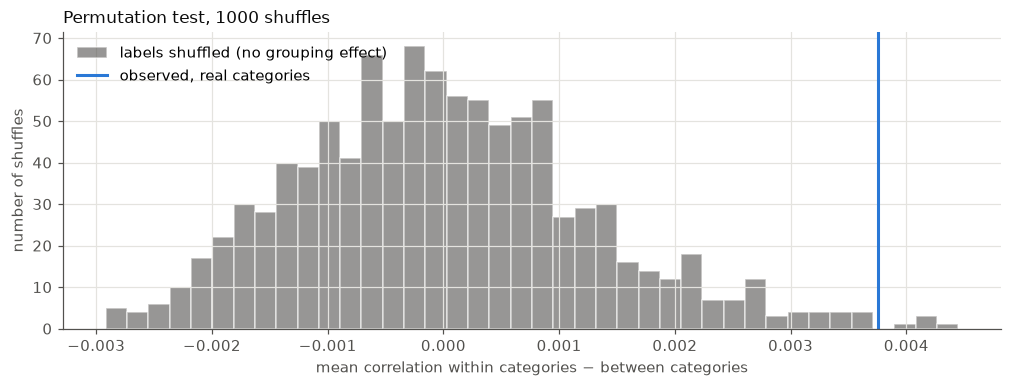

In [17]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.hist(result["null_gaps"], bins=40, color=MUTED_TEXT_COLOR, alpha=0.6, edgecolor="white",
        label="labels shuffled (no grouping effect)")
ax.axvline(result["gap"], color=MAIN_COLOR, linewidth=2, label="observed, real categories")
ax.set_xlabel("mean correlation within categories − between categories")
ax.set_ylabel("number of shuffles")
ax.set_title(f"Permutation test, {N_PERMUTATIONS} shuffles", loc="left")
ax.legend(loc="upper left")
plt.show()

**Robustness.** The result must not depend on the shift tolerance we picked. Same test with no tolerance and
with a full week (about 10 to 30 seconds per line).

In [18]:
robustness = []
for tolerance in (0, 3, 7):
    corr = pairwise_blank_correlation(tolerate_shifts(blank_matrix, tolerance), on_sale_matrix, MIN_COMMON_DAYS)
    test = grouping_permutation_test(corr, category_labels, N_PERMUTATIONS, SEED)
    robustness.append({
        "shift_tolerance_days": tolerance,
        "all_pairs": test["all_pairs"],
        "within": test["within"],
        "between": test["between"],
        "z_score": test["z_score"],
        "p_value": test["p_value"],
    })
pl.DataFrame(robustness)

shift_tolerance_days,all_pairs,within,between,z_score,p_value
i64,f64,f64,f64,f64,f64
0,0.007751,0.010041,0.006479,3.029312,0.005994
3,0.008478,0.010894,0.007136,2.97312,0.005994
7,0.009573,0.012125,0.008154,2.88736,0.008991


**How to read it.** Category is a useful grouping only if, for every tolerance, the observed gap sits clearly
to the right of the shuffled ones (z around 2 or more, p below 0.05) **and** the within-category correlation
is clearly larger than the all-pairs one. A significant but tiny gap would mean category is technically
related to blank periods, but too weakly to justify treating categories separately.

## 7. Are blank periods shared within a store?

For each store and day: the share of its on-sale series that are inside a blank period.
A store-wide event would appear as a dark vertical stripe on one row.

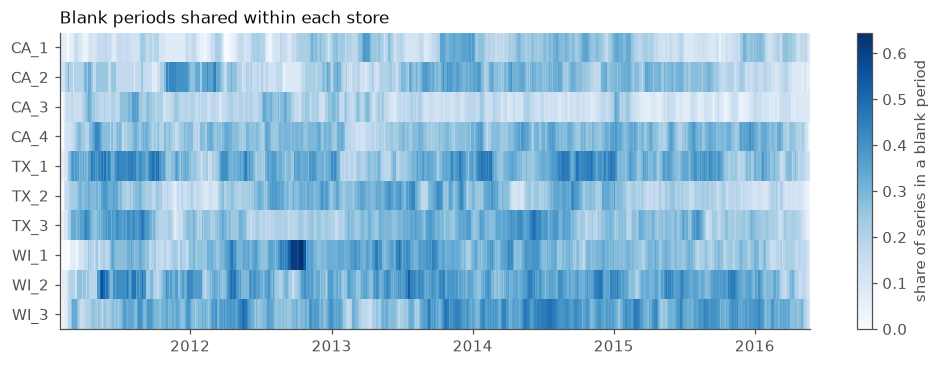

store_id,col,share_blank,date
str,i64,f64,date
"""WI_1""",622,0.645161,2012-10-12
"""WI_1""",625,0.645161,2012-10-15
"""WI_1""",627,0.645161,2012-10-17
"""WI_1""",626,0.645161,2012-10-16
"""WI_1""",624,0.645161,2012-10-14


In [19]:
store_share = (
    sales.filter(pl.col("is_on_sale"))
    .group_by("store_id", "col")
    .agg(pl.col("is_blank").mean().alias("share_blank"))
)

stores = sorted(roster["store_id"].unique().to_list())
store_matrix = np.zeros((len(stores), n_cols))
for i, store in enumerate(stores):
    one_store = store_share.filter(pl.col("store_id") == store)
    store_matrix[i, one_store["col"].to_numpy()] = one_store["share_blank"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 3.5))
picture = ax.imshow(store_matrix, aspect="auto", interpolation="nearest", cmap="Blues", vmin=0)
ax.grid(False)
ax.set_yticks(range(len(stores)))
ax.set_yticklabels(stores)
years = sales.filter(pl.col("date").dt.month() == 1, pl.col("date").dt.day() == 1).unique("date").sort("date")
ax.set_xticks(years["col"].to_list())
ax.set_xticklabels(years["date"].dt.year().to_list())
fig.colorbar(picture, ax=ax, label="share of series in a blank period")
ax.set_title("Blank periods shared within each store", loc="left")
plt.show()

# The 5 (store, day) pairs with the highest share
store_share.sort("share_blank", descending=True).head(5).with_columns(
    (pl.lit(first_date) + pl.duration(days=pl.col("col"))).alias("date")
)

## 8. Days when everything stops

Days where the whole sample sold (almost) nothing. These are observed zeros shared by every series.

In [20]:
daily_total = sales.group_by("date").agg(pl.col("sales").sum().alias("total_sales")).sort("date")
daily_total.filter(pl.col("total_sales") < 0.1 * daily_total["total_sales"].median())

date,total_sales
date,i64
2011-12-25,1
2012-12-25,0
2013-12-25,0
2014-12-25,0
2015-12-25,0


## 9. Save the flags for the next notebooks

In [21]:
output_path = ARTIFACTS_DIR / f"sales_flags_{roster_name(SAMPLE_SIZE, SEED)}.parquet"
sales.select(
    "id", "item_id", "dept_id", "cat_id", "store_id", "state_id", "date", "sales",
    "sell_price", "is_missing", "silent_run_length", "is_blank", "blank_kind",
).write_parquet(output_path)
print(f"Saved to {output_path.name}")

Saved to sales_flags_n500_seed42.parquet


## Notes

*Your observations here.*